# 03 — Baselines

**Question:** how well can next week be forecast from past seismicity alone? These simple forecasts set the bar: the paper's model (later in this notebook) and the machine-learning models of phase 6 are only useful if they beat them.

**Setup** (`src/evaluation.py`):

- **Targets**, per week (Monday to Sunday, UTC): the number of events with M ≥ 0.6 (`MC_MAIN`, from `01_completeness`), and whether the week had at least one event with M ≥ 3.
- **Walk-forward evaluation:** each test week is forecast using only the weeks before it, then the window moves on by one week. Nothing is shuffled, and no forecast sees its own week or later.
- **Test period:** January 2020 to December 2025 (312 weeks). Before 2020 most weeks have no events, which would make scores easy and uninformative; the GPS record ends in December 2025. History for every forecast starts in January 2005. Results for 2023–2025, the busiest years, are also shown separately.
- **Scores:**
  - Counts: **Poisson deviance**, the standard score for count forecasts (0 is perfect, lower is better; it punishes forecasting too few events in a busy week heavily, and forecasting zero when events happen infinitely, so forecasts are floored at 0.1 events), and **mean absolute error** (MAE) in events per week, which is easier to read.
  - M ≥ 3: **Brier score** (mean squared error of the probability) and **log-loss** (penalises confident wrong forecasts heavily), both lower is better; and **calibration**: when we say 20%, does it happen about 20% of the time?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import (make_climatology, make_from_count, make_rolling_mean, make_trend,
                           persistence)
from src.evaluation import (calibration_table, count_scores, probability_scores,
                            walk_forward, weekly_targets)

events = pd.read_parquet("../data/processed/catalogue.parquet")
weekly = weekly_targets(events, start="2005-01-03", end="2025-12-28")
TEST_START, TEST_END = "2020-01-06", "2025-12-22"
test = weekly.loc[TEST_START:TEST_END]
print(f"History from {weekly.index[0]:%Y-%m-%d}; {len(test)} test weeks "
      f"{test.index[0]:%Y-%m-%d} to {test.index[-1]:%Y-%m-%d}")
test.groupby(test.index.year).agg(weeks=("count", "size"), events=("count", "sum"),
                                  median_per_week=("count", "median"),
                                  max_per_week=("count", "max"),
                                  weeks_with_M3=("has_large", "sum"))

History from 2005-01-03; 312 test weeks 2020-01-06 to 2025-12-22


,weeks,events,median_per_week,max_per_week,weeks_with_M3
period_start,,,,,
2020,52,148,1.5,19,1
2021,52,165,2.0,19,0
2022,52,299,5.5,32,2
2023,52,918,10.5,126,10
2024,53,1452,17.0,160,14
2025,51,2189,28.0,334,16


## 1. Forecasting the weekly count

Five baselines (`src/baselines.py`):

- **Persistence:** next week = this week.
- **Rolling mean, 4 or 12 weeks:** next week = the average of the last 4 or 12 weeks.
- **Trend, 52 or 104 weeks:** a Poisson regression of weekly counts on time over the last one or two years, extrapolated one week ahead. Phase 4 showed the rate doubling about every 1.5 years; this baseline uses that.

In [2]:
count_forecasters = [persistence, make_rolling_mean(4), make_rolling_mean(12),
                     make_trend(52), make_trend(104)]
count_forecasts = {f.__name__: walk_forward(weekly, f, TEST_START, TEST_END) for f in count_forecasters}

recent = test.index >= "2023-01-01"
pd.concat({
    "2020–2025": count_scores(test["count"], count_forecasts),
    "2023–2025": count_scores(test["count"][recent], {n: f[recent] for n, f in count_forecasts.items()}),
}, axis=1).round(2)

2020–2025               2023–2025       
                 poisson_deviance    mae poisson_deviance    mae
persistence                 15.99  12.16            24.11  20.70
rolling_mean_4w             14.81  12.07            25.35  21.26
rolling_mean_12w            17.70  12.79            30.82  22.48
trend_52w                   19.38  13.70            34.04  24.14
trend_104w                  17.21  13.43            30.11  23.75

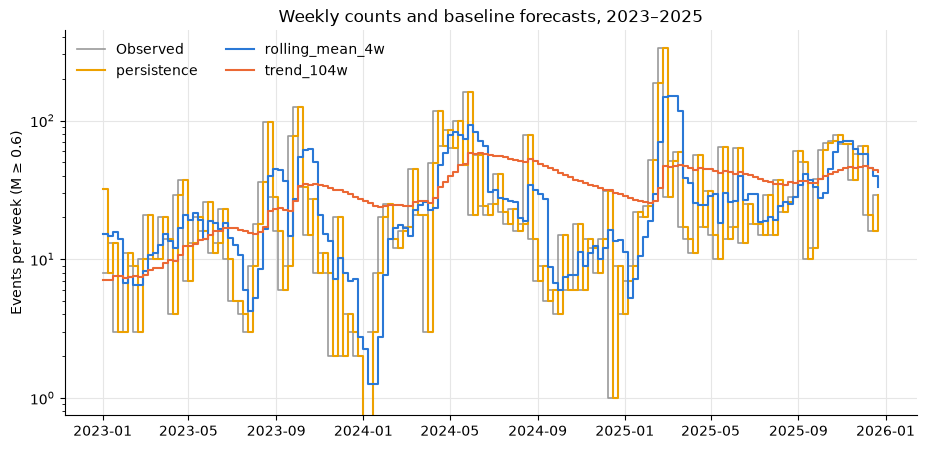

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
shown = test.loc["2023-01-01":]
ax.plot(shown.index, shown["count"].where(shown["count"] > 0), drawstyle="steps-post", color="0.6",
        linewidth=1.2, label="Observed")
for name, colour in [("persistence", "#eda100"), ("rolling_mean_4w", "#2a78d6"), ("trend_104w", "#eb6834")]:
    f = count_forecasts[name].loc["2023-01-01":]
    ax.plot(f.index, f, drawstyle="steps-post", linewidth=1.5, color=colour, label=name)
ax.set_yscale("log")
ax.set_ylabel("Events per week (M ≥ 0.6)")
ax.set_title("Weekly counts and baseline forecasts, 2023–2025")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

## 2. Forecasting P(at least one M ≥ 3 next week)

- **Climatology:** the share of past weeks with an M ≥ 3 event, over all history or the last 52 weeks.
- **From a count forecast:** P = 1 − exp(−expected count × share), where share is the fraction of events with M ≥ 0.6 that reached M ≥ 3 over the last 3 years. This assumes events within a week are independent, which swarms violate; it uses the observed share rather than a Gutenberg–Richter b-value (which phase 4 found underpredicts large events).

For reference: 43 of the 312 test weeks (13.8%) had an M ≥ 3 event. A forecaster that always said 13.8% would score Brier 0.119, but it would be cheating, since it uses the answer.

In [4]:
prob_forecasters = [make_climatology(), make_climatology(52),
                    make_from_count(make_rolling_mean(4)), make_from_count(make_rolling_mean(12)),
                    make_from_count(make_trend(104))]
prob_forecasts = {f.__name__: walk_forward(weekly, f, TEST_START, TEST_END) for f in prob_forecasters}

pd.concat({
    "2020–2025": probability_scores(test["has_large"], prob_forecasts),
    "2023–2025": probability_scores(test["has_large"][recent], {n: p[recent] for n, p in prob_forecasts.items()}),
}, axis=1).round(3)

2020–2025                 2023–2025                
                          brier log_loss mean_p     brier log_loss mean_p
climatology_all           0.132    0.573  0.012     0.245    1.025  0.021
climatology_52w           0.107    0.357  0.118     0.195    0.597  0.213
from_rolling_mean_4w      0.107    0.335  0.150     0.194    0.576  0.277
from_rolling_mean_12w     0.114    0.355  0.154     0.209    0.611  0.286
from_trend_104w           0.115    0.359  0.179     0.211    0.615  0.334

In [5]:
# Calibration of the best baseline: do forecast probabilities match how often M >= 3 happened?
calibration_table(test["has_large"], prob_forecasts["from_rolling_mean_4w"]).round(3)

,weeks,mean_forecast,observed_share
forecast_bin,,,
"(-0.001, 0.05]",157,0.021,0.019
"(0.05, 0.1]",45,0.071,0.111
"(0.1, 0.2]",26,0.146,0.192
"(0.2, 0.3]",19,0.251,0.368
"(0.3, 1.0]",65,0.489,0.354


**What the baselines show:**

- **Counts: short memory wins.** The 4-week rolling mean scores best over 2020–2025 (Poisson deviance 14.8, MAE 12.1 events/week), with persistence close behind (16.0) and even slightly better in 2023–2025 (24.1 vs 25.4). Longer windows and the trend models do worse: after a swarm they stay high for months (the trend lines in the plot), and they react slowly to sudden changes. The rate changes faster than any smooth trend.
- **Errors are large.** An MAE of 12 events/week (20 in 2023–2025) against a median of 10–28 events/week shows how bursty the seismicity is: swarms arrive with little warning in the count series itself. The plot shows persistence as the observed series shifted by one week; it is always one swarm late.
- **M ≥ 3: the 4-week count turned into a probability is best** (Brier 0.107, log-loss 0.335), just ahead of the 52-week climatology. Climatology over all history is poor (it averages in the quiet early years and forecasts about 1%).
- **Calibration is decent at low probabilities but off at the top:** weeks forecast below 5% had an M ≥ 3 2% of the time (forecast 2%), but weeks forecast above 30% (mean 49%) had one only 35% of the time, and the middle bins are under-forecast. The Poisson conversion is over-confident after big swarms, when many events but not proportionally many M ≥ 3 follow.

**The bar for later models:** Poisson deviance 14.8 (2020–2025) and 24.1 (2023–2025) for counts; Brier 0.107 and log-loss 0.335 for M ≥ 3. Next in this notebook: the paper's model.

## 3. Reproducing the paper's model (arXiv 2503.20129)

Godano et al. (2025) relate the cumulative number of earthquakes N to the uplift δ (cm) at RITE:

  dN/dδ = β · δ^α · N · ln N   (their Eq. 4)

- **N:** earthquakes trigger more earthquakes (the "epidemic" part).
- **ln N:** saturation.
- **δ^α with α < 0:** triggering gets less efficient as uplift grows.

Solving gives ln(ln N) = β/(α+1) · δ^(α+1) + C. They fit **ln(ln N) = k₁ · δ^k₂** by least squares, so implicitly C = 0, and report **k₁ = 0.76, k₂ = 0.2**, so α = k₂ − 1 = −0.8 and β = k₁·k₂ = 0.15. They also fit a plain exponential N = 35.25 · e^(0.035 δ). They leave out the first 30 earthquakes.

**Their data, as reconstructed in `01_completeness`:** located events with M > 0.5 (with 0.1 bins, the same as M ≥ 0.6), from January 2005 to about 21 May 2024 (or June 2024). δ is RITE's vertical displacement relative to January 2005, smoothed with a 15-day median (`src/paper_model.py`). Each event gets the δ of its day and its running number N.

In [6]:
from src.completeness import MC_MAIN, bin_magnitudes
from src.paper_model import (PAPER_PARAMS, event_uplift_table, fit_double_log, fit_exponential,
                             predict_n, uplift_cm)

gps = pd.read_parquet("../data/processed/gps_daily.parquet")
delta = uplift_cm(gps)  # RITE, cm since January 2005
m_binned = bin_magnitudes(events["md"])
paper_events = events[events["has_location"] & (m_binned > 0.5 + 1e-9)]
our_events = events[m_binned >= MC_MAIN - 1e-9]

tables = {
    "paper set, to 21 May 2024": event_uplift_table(paper_events, delta, "2005-01-01", "2024-05-22"),
    "paper set, to 30 Jun 2024": event_uplift_table(paper_events, delta, "2005-01-01", "2024-07-01"),
    "ours (all M ≥ 0.6), to Dec 2025": event_uplift_table(our_events, delta, "2005-01-01", "2026-01-01"),
}
rows = {"paper (reported)": {**PAPER_PARAMS, "c": 0.0}}
for name, table in tables.items():
    rows[name] = {**fit_double_log(table), **fit_exponential(table),
                  "last_delta_cm": table["delta"].iloc[-1], "last_N": table["N"].iloc[-1]}
rows["paper set to 21 May 2024, C free"] = fit_double_log(tables["paper set, to 21 May 2024"], with_constant=True)
fits = pd.DataFrame(rows).T[["k1", "k2", "c", "alpha", "beta", "N0", "b", "events", "last_delta_cm", "last_N"]]
fits.astype(float).round(3)

,k1,k2,c,alpha,beta,N0,b,events,last_delta_cm,last_N
paper (reported),0.760,0.200,0.00,-0.800,0.150,35.250,0.035,NaN,NaN,NaN
"paper set, to 21 May 2024",0.752,0.205,0.00,-0.795,0.154,19.874,0.038,2684.0,127.809,2714.0
"paper set, to 30 Jun 2024",0.744,0.208,0.00,-0.792,0.155,17.655,0.039,2863.0,130.825,2893.0
"ours (all M ≥ 0.6), to Dec 2025",0.757,0.205,0.00,-0.795,0.156,74.929,0.027,5493.0,161.241,5523.0
"paper set to 21 May 2024, C free",0.046,0.613,1.15,-0.387,0.028,NaN,NaN,2684.0,NaN,NaN


**How well do the curves fit, and do they carry on after the paper's data ends?** Left: N against δ on a log scale (like the paper's Fig. 3). Right: ln(ln N) against δ on log-log axes (like their Fig. 4), where their model is a straight line. Fits use the paper set to 21 May 2024. Grey points after that date (to December 2025, same event selection) were not used in the fit: they test whether the curves extrapolate.

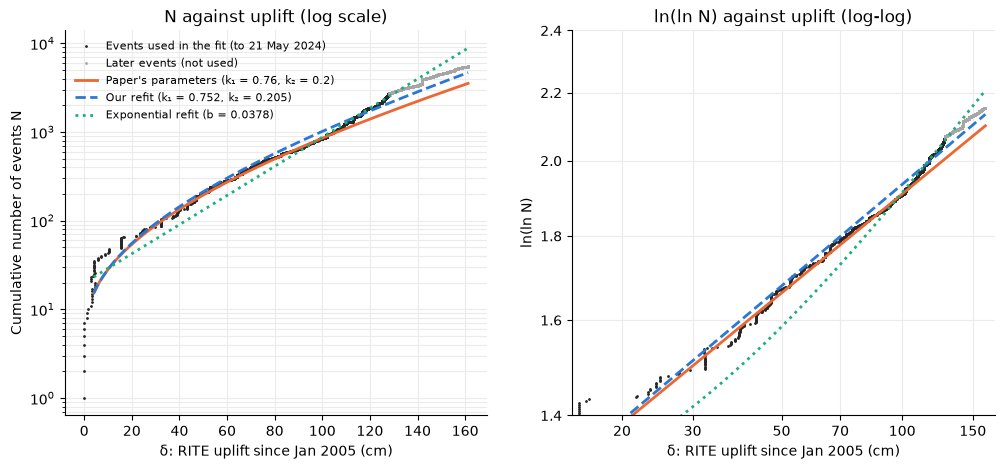

End of 2025: δ = 161.2 cm, observed N = 5,498
  predicted by paper's parameters: 3,532
  predicted by our refit: 4,676
  predicted by exponential refit: 8,854


In [7]:
fit_table = tables["paper set, to 21 May 2024"]
later = event_uplift_table(paper_events, delta, "2024-05-22", "2026-01-01")
later["N"] += fit_table["N"].iloc[-1]  # continue the count
fit_ours = fit_double_log(fit_table)
fit_exp = fit_exponential(fit_table)
d_grid = np.linspace(4, later["delta"].max(), 300)

fig, (ax_n, ax_ll) = plt.subplots(1, 2, figsize=(12, 5))
for ax, transform in [(ax_n, lambda n: n), (ax_ll, lambda n: np.log(np.log(np.where(np.asarray(n) > 1, n, np.nan))))]:
    ax.plot(fit_table["delta"], transform(fit_table["N"]), ".", markersize=2, color="0.15", label="Events used in the fit (to 21 May 2024)")
    ax.plot(later["delta"], transform(later["N"]), ".", markersize=2, color="0.65", label="Later events (not used)")
    ax.plot(d_grid, transform(predict_n(d_grid, PAPER_PARAMS["k1"], PAPER_PARAMS["k2"])), color="#eb6834",
            linewidth=2, label="Paper's parameters (k₁ = 0.76, k₂ = 0.2)")
    ax.plot(d_grid, transform(predict_n(d_grid, fit_ours["k1"], fit_ours["k2"])), "--", color="#2a78d6",
            linewidth=2, label=f"Our refit (k₁ = {fit_ours['k1']:.3f}, k₂ = {fit_ours['k2']:.3f})")
    ax.plot(d_grid, transform(fit_exp["N0"] * np.exp(fit_exp["b"] * d_grid)), ":", color="#1baf7a",
            linewidth=2, label=f"Exponential refit (b = {fit_exp['b']:.4f})")
    ax.grid(True, which="both", color="0.92", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("δ: RITE uplift since Jan 2005 (cm)")
ax_n.set_yscale("log")
ax_n.set_ylabel("Cumulative number of events N")
ax_n.set_title("N against uplift (log scale)")
ax_ll.set_xscale("log")
ax_ll.set_yscale("log")
ax_ll.set_xlim(15, 170)
ax_ll.set_ylim(1.4, 2.4)
ax_ll.set_xticks([20, 30, 50, 70, 100, 150], ["20", "30", "50", "70", "100", "150"])
ax_ll.set_yticks([1.4, 1.6, 1.8, 2.0, 2.2, 2.4], ["1.4", "1.6", "1.8", "2.0", "2.2", "2.4"])
ax_ll.minorticks_off()
ax_ll.set_ylabel("ln(ln N)")
ax_ll.set_title("ln(ln N) against uplift (log-log)")
ax_n.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

end = later.iloc[-1]
print(f"End of 2025: δ = {end['delta']:.1f} cm, observed N = {end['N']:,}")
for name, n in [("paper's parameters", predict_n(end["delta"], PAPER_PARAMS["k1"], PAPER_PARAMS["k2"])),
                ("our refit", predict_n(end["delta"], fit_ours["k1"], fit_ours["k2"])),
                ("exponential refit", fit_exp["N0"] * np.exp(fit_exp["b"] * end["delta"]))]:
    print(f"  predicted by {name}: {n:,.0f}")

**What the reproduction shows:**

- **The paper's fit is reproduced.** On the reconstructed paper data (located events with M > 0.5, to 21 May 2024, first 30 left out), least squares on ln(ln N) = k₁·δ^k₂ gives **k₁ = 0.752, k₂ = 0.205**, so α = −0.795 and β = 0.154, against the reported 0.76, 0.2, −0.8 and 0.15. Ending in June 2024, or using all our events with M ≥ 0.6 to December 2025, gives almost the same values (k₂ = 0.205–0.208). The parameters are stable.
- **But the parameters depend entirely on fixing C = 0.** With the constant C left free (it's part of the paper's own solution, Eq. 6), the same data give k₂ = 0.61 and α = −0.39, a very different model that fits about as well. The data alone don't pin down α and β.
- **The curve underpredicts recent counts.** The paper's parameters give about 1,700 events at δ = 128 cm, where 2,714 had happened. On the log-log plot the data bend upwards above about 110 cm (from 2023 on), away from the straight line. This is hidden in ln(ln N) space: an error of 0.05 there, which looks small, is a factor of about 1.5 in N at N ≈ 3,000. Least squares in this space gives little weight to the recent, most numerous events.
- **Extrapolation to 2025 (not used in any fit):** by the end of 2025 (δ = 161 cm) 5,498 events had happened in the paper's event set. The paper's parameters predict 3,532 (−36%), our refit to May 2024 predicts 4,676 (−15%), and the plain exponential 8,854 (+61%). So the double-log model extrapolates better than the exponential, as the paper argues, but still falls short.
- **What this means for forecasting.** The paper's model describes the *cumulative* curve, and its parameters come from a fit that treats thousands of overlapping points as independent. For weekly forecasts, the same equation can be written as a rate, dN/dt = β·δ^α·N·ln N·dδ/dt, and fitted directly to weekly counts by Poisson likelihood. That's the next step, scored with the same walk-forward evaluation as the baselines.